# Lecture 6 — Class Exercise
## Choropleth Maps

> **Push to:** `week06/lecture06_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


In [2]:
%pip install plotly nbformat
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


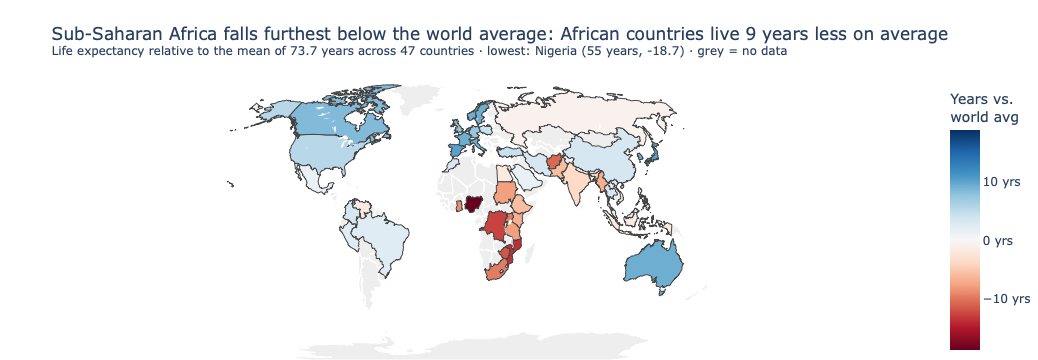

In [9]:
# Task 1 — World choropleth: life expectancy vs. the global average

gm = pd.read_csv("gapminder.csv")   # must be in the same folder as the notebook

# Deviation from the (unweighted) global mean life expectancy
global_mean = gm["Life_expectancy"].mean()
gm["deviation"] = gm["Life_expectancy"] - global_mean

# The CSV has country names only -> add ISO-3 codes so plotly can place each country
ISO3 = {
    "Afghanistan": "AFG", "Australia": "AUS", "Bangladesh": "BGD", "Brazil": "BRA",
    "Canada": "CAN", "China": "CHN", "Colombia": "COL", "DR Congo": "COD",
    "Egypt": "EGY", "Ethiopia": "ETH", "France": "FRA", "Germany": "DEU",
    "Ghana": "GHA", "India": "IND", "Indonesia": "IDN", "Iran": "IRN",
    "Italy": "ITA", "Japan": "JPN", "Kenya": "KEN", "Malaysia": "MYS",
    "Mexico": "MEX", "Morocco": "MAR", "Mozambique": "MOZ", "Myanmar": "MMR",
    "Netherlands": "NLD", "Nigeria": "NGA", "Norway": "NOR", "Pakistan": "PAK",
    "Peru": "PER", "Philippines": "PHL", "Poland": "POL", "Russia": "RUS",
    "Saudi Arabia": "SAU", "South Africa": "ZAF", "South Korea": "KOR", "Spain": "ESP",
    "Sudan": "SDN", "Sweden": "SWE", "Tanzania": "TZA", "Thailand": "THA",
    "Turkey": "TUR", "Uganda": "UGA", "UK": "GBR", "USA": "USA",
    "Venezuela": "VEN", "Vietnam": "VNM", "Zimbabwe": "ZWE",
}
gm["iso3"] = gm["Country"].map(ISO3)
assert gm["iso3"].notna().all(), f"No ISO code for: {gm.loc[gm['iso3'].isna(), 'Country'].tolist()}"

# Numbers for the insight title, computed rather than hard-coded
africa_gap = gm.loc[gm["Continent"] == "Africa", "deviation"].mean()
worst = gm.loc[gm["deviation"].idxmin()]

# Symmetric colour range so that zero (= world average) sits exactly on the neutral midpoint
max_abs = gm["deviation"].abs().max()

fig1 = px.choropleth(
    gm,
    locations="iso3",                   # ISO-3 codes match plotly's built-in world geometry
    color="deviation",
    hover_name="Country",
    hover_data={
        "iso3": False,
        "Life_expectancy": ":.0f",
        "deviation": ":+.1f",
    },
    labels={
        "Life_expectancy": "Life expectancy (years)",
        "deviation": "Deviation from world average (years)",
    },
    color_continuous_scale="RdBu",      # diverging: red = below average, blue = above
    color_continuous_midpoint=0,
    range_color=[-max_abs, max_abs],
    projection="natural earth",
    title=(
        f"Sub-Saharan Africa falls furthest below the world average: African countries "
        f"live {abs(africa_gap):.0f} years less on average<br>"
        f"<sup>Life expectancy relative to the mean of {global_mean:.1f} years across "
        f"{len(gm)} countries · lowest: {worst['Country']} "
        f"({worst['Life_expectancy']:.0f} years, {worst['deviation']:+.1f}) · grey = no data</sup>"
    ),
)

fig1.update_geos(
    showframe=False, showcoastlines=False,
    showland=True, landcolor="#eeeeee",          # countries without data stay light grey
    showcountries=True, countrycolor="white",
)
fig1.update_layout(
    coloraxis_colorbar=dict(title="Years vs.<br>world avg", ticksuffix=" yrs"),
    margin=dict(l=0, r=0, t=80, b=0),
)
fig1.show()

## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** *(Natural Earth 1:110m country polygons (admin 0), found via [geojson.xyz](https://geojson.xyz/):
https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_admin_0_countries.geojson)*

**Chart type chosen** (`px.choropleth` or `px.choropleth_mapbox`) **and reason:**

*px.choropleth, because world-scale country data needs no tile basemap and the Natural Earth projection distorts areas less than Web Mercator.*

**Colour scale chosen** (sequential or diverging) **and reason:**

*sequential, because the fossil share only runs one way (0–100%) and has no natural midpoint.*


{'scalerank': 1, 'labelrank': 3, 'sovereignt': 'Afghanistan', 'sov_a3': 'AFG', 'adm0_dif': 0, 'level': 2, 'type': 'Sovereign country', 'admin': 'Afghanistan', 'adm0_a3': 'AFG', 'geou_dif': 0, 'geounit': 'Afghanistan', 'gu_a3': 'AFG', 'su_dif': 0, 'subunit': 'Afghanistan', 'su_a3': 'AFG', 'brk_diff': 0, 'name': 'Afghanistan', 'name_long': 'Afghanistan', 'brk_a3': 'AFG', 'brk_name': 'Afghanistan', 'brk_group': None, 'abbrev': 'Afg.', 'postal': 'AF', 'formal_en': 'Islamic State of Afghanistan', 'formal_fr': None, 'note_adm0': None, 'note_brk': None, 'name_sort': 'Afghanistan', 'name_alt': None, 'mapcolor7': 5, 'mapcolor8': 6, 'mapcolor9': 8, 'mapcolor13': 7, 'pop_est': 28400000, 'gdp_md_est': 22270, 'pop_year': -99, 'lastcensus': 1979, 'gdp_year': -99, 'economy': '7. Least developed region', 'income_grp': '5. Low income', 'wikipedia': -99, 'fips_10': None, 'iso_a2': 'AF', 'iso_a3': 'AFG', 'iso_n3': '004', 'un_a3': '004', 'wb_a2': 'AF', 'wb_a3': 'AFG', 'woe_id': -99, 'adm0_a3_is': 'AFG', '

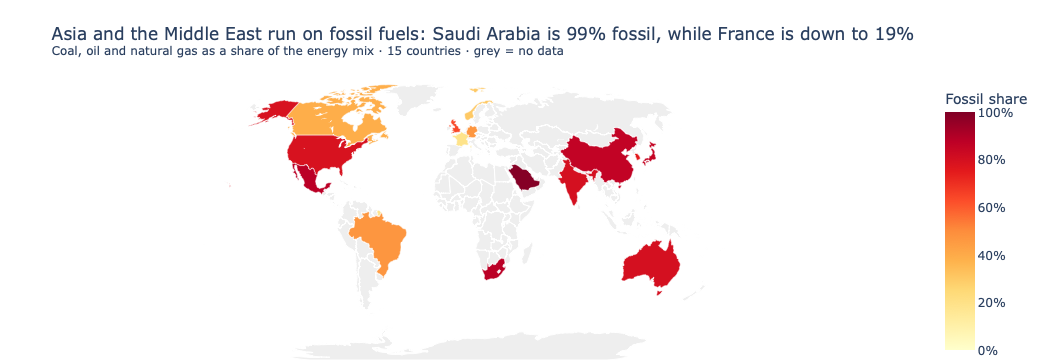

In [8]:
# Task 2 — Fossil-fuel share of the energy mix by country

# --- Load the GeoJSON ------------------------------------------------------
GEOJSON_URL = (
    "https://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/"
    "ne_110m_admin_0_countries.geojson"
)
try:                                    # browser kernel (Pyodide / Try Jupyter)
    from pyodide.http import open_url
    my_geojson = json.load(open_url(GEOJSON_URL))
except ImportError:                     # normal local Python
    from urllib.request import urlopen
    with urlopen(GEOJSON_URL) as response:
        my_geojson = json.load(response)

# --- Inspect the properties to find the right featureidkey -----------------
print(my_geojson["features"][0]["properties"])
# 'adm0_a3' is a 3-letter country code filled in for every feature
# -> featureidkey = "properties.adm0_a3"
FEATURE_KEY = "adm0_a3"

# --- Load and reshape the dataset ------------------------------------------
energy = pd.read_csv("global_energy_mix.csv")   # must be in the same folder as the notebook

FOSSIL = ["Coal", "Oil", "Natural Gas"]
energy["is_fossil"] = energy["Source"].isin(FOSSIL)

# one row per country: fossil share (%) and the single largest source
fossil_share = (
    energy[energy["is_fossil"]]
    .groupby(["Country", "Region"], as_index=False)["Share_pct"].sum()
    .rename(columns={"Share_pct": "fossil_share"})
)
top_source = (
    energy.sort_values("Share_pct", ascending=False)
    .drop_duplicates("Country")[["Country", "Source", "Share_pct"]]
    .rename(columns={"Source": "top_source", "Share_pct": "top_source_share"})
)
mix = fossil_share.merge(top_source, on="Country")

# The CSV has country names, the GeoJSON key is a 3-letter code -> add a matching column
ISO3 = {
    "United States": "USA", "Canada": "CAN", "Mexico": "MEX", "Brazil": "BRA",
    "United Kingdom": "GBR", "France": "FRA", "Germany": "DEU", "Norway": "NOR",
    "China": "CHN", "India": "IND", "Japan": "JPN", "South Korea": "KOR",
    "Saudi Arabia": "SAU", "South Africa": "ZAF", "Australia": "AUS",
}
mix["iso3"] = mix["Country"].map(ISO3)

# --- Sanity check: every country must have a code that exists in the GeoJSON
geo_ids = {f["properties"][FEATURE_KEY] for f in my_geojson["features"]}
unmatched = mix.loc[~mix["iso3"].isin(geo_ids), "Country"].tolist()
assert not unmatched, f"No GeoJSON match for: {unmatched}"

mix = mix.sort_values("fossil_share")
lowest, highest = mix.iloc[0], mix.iloc[-1]

# --- Choropleth ------------------------------------------------------------
fig2 = px.choropleth(
    mix,
    geojson=my_geojson,
    locations="iso3",
    featureidkey=f"properties.{FEATURE_KEY}",
    color="fossil_share",
    color_continuous_scale="YlOrRd",    # sequential: one-directional magnitude
    range_color=[0, 100],
    hover_name="Country",
    hover_data={
        "iso3": False,
        "Region": True,
        "fossil_share": ":.0f",
        "top_source": True,
        "top_source_share": ":.0f",
    },
    labels={
        "fossil_share": "Fossil share (%)",
        "top_source": "Largest source",
        "top_source_share": "Largest source share (%)",
    },
    projection="natural earth",
    title=(
        "Asia and the Middle East run on fossil fuels: "
        f"{highest['Country']} is {highest['fossil_share']:.0f}% fossil, "
        f"while {lowest['Country']} is down to {lowest['fossil_share']:.0f}%<br>"
        "<sup>Coal, oil and natural gas as a share of the energy mix · 15 countries · "
        "grey = no data</sup>"
    ),
)
fig2.update_geos(
    showframe=False, showcoastlines=False,
    showland=True, landcolor="#eeeeee",          # countries without data stay light grey
    showcountries=True, countrycolor="white",
)
fig2.update_traces(marker_line_color="white", marker_line_width=0.5)
fig2.update_layout(
    coloraxis_colorbar=dict(title="Fossil share", ticksuffix="%"),
    margin=dict(l=0, r=0, t=80, b=0),
)
fig2.show()